# Global Photometry: Masks, Apertures and Quality Flags

This example goes through the global photometry of a large spiral galaxy, NGC 1015 (host of SN 2009ig), with the options introduced in HostPhot v4:

* masking with a model of the host galaxy (`method="host_model"`), so that only the stars and the sources much brighter than the galaxy are masked;
* curve-of-growth apertures (`aperture_method="cog"`), which include the faint outskirts of the galaxy;
* masks and apertures measured on a PanSTARRS coadd and transferred to other surveys (2MASS and WISE) through their ellipses on the sky;
* the output columns (AB magnitudes, flux densities in µJy, upper limits) and the quality flags.

In [1]:
import hostphot
print('HostPhot version:', hostphot.__version__)

HostPhot version: 4.0.0


In [2]:
import pandas as pd
from hostphot.utils import plot_image
from hostphot.cutouts import download_images
from hostphot.processing import coadd_images, create_mask
from hostphot.photometry import global_photometry as gp

name = 'SN2009ig'
ra, dec = 39.548375, -1.312556  # SN
host_ra, host_dec = 39.5482, -1.3187  # NGC 1015
z = 0.0088

## Cutouts

The galaxy is ~2.6 arcmin across, so 7-arcmin cutouts are downloaded: the background estimation and the uncertainties (from blank apertures) need sky around the galaxy, and HostPhot warns when the images are too small for that:

In [3]:
surveys = ['PanSTARRS', '2MASS', 'WISE']
for survey in surveys:
    download_images(name, host_ra, host_dec, survey=survey, size=7, overwrite=False)

## Masking

The masks are measured on a coadd of the PanSTARRS *riz* images, where the faint sources are detected best. With the default method (`method="ellipses"`), every detected source except the host is masked with an ellipse. With `crossmatch=True`, only the sources that are stars in Gaia DR3 (with significant proper motion or parallax) are masked, which avoids masking the bright HII regions of nearby galaxies:

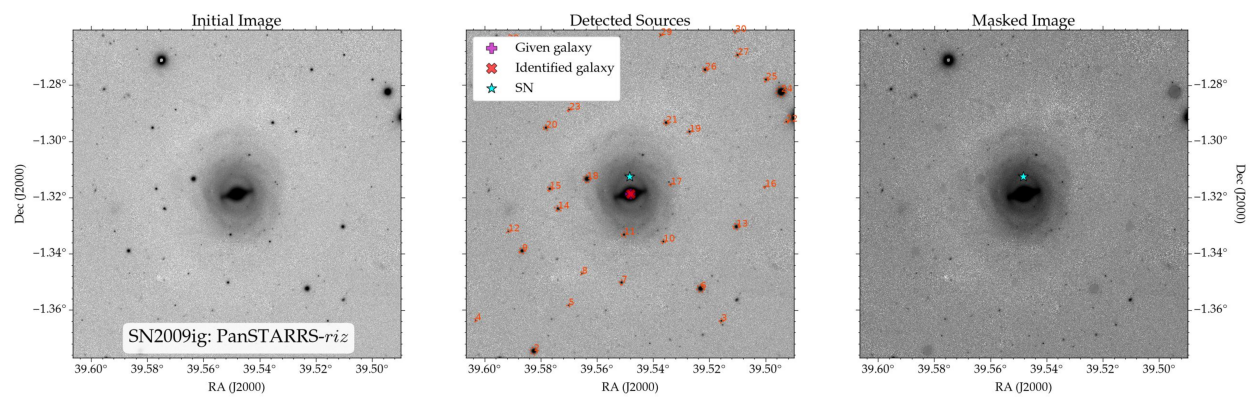

In [4]:
coadd_images(name, filters='riz', survey='PanSTARRS')

create_mask(name, host_ra, host_dec, filt='riz', survey='PanSTARRS',
            ra=ra, dec=dec,  # only used to plot the SN position
            crossmatch=True,
            save_plots=True)
plot_image(f'images/{name}/PanSTARRS/PanSTARRS_riz_masked.jpg')

With `method="host_model"`, the host is modelled with a Sérsic profile and, within the host region (green contour), only the Gaia stars and the sources much brighter than the galaxy where they lie are masked; the masked pixels are filled with the model plus noise. Outside the host region, the sources are masked as before. This keeps the light of the galaxy (its HII regions, spiral arms or bulge) when masking large or nearby galaxies.

`save_mask_params=True` stores the mask parameters (and their ellipses on the sky), so that the same mask can be applied to other filters and surveys:

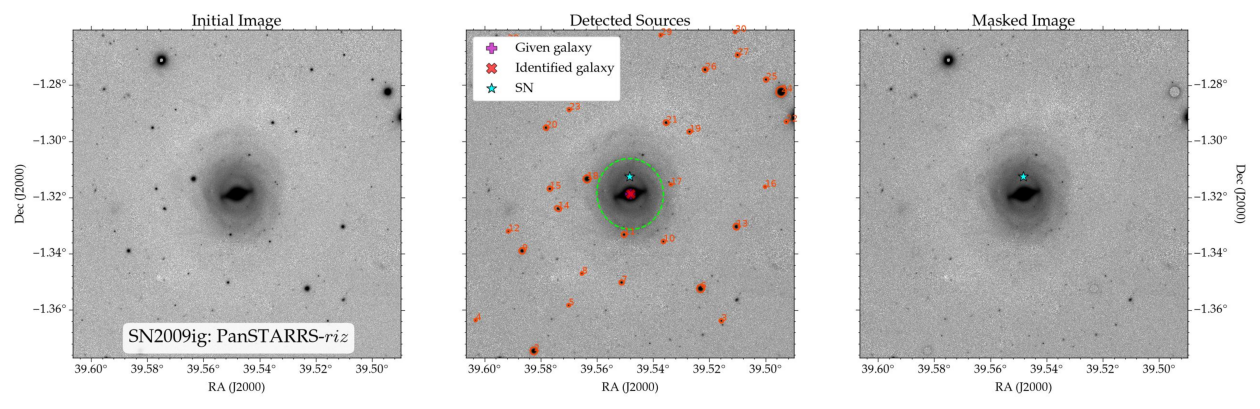

In [5]:
create_mask(name, host_ra, host_dec, filt='riz', survey='PanSTARRS',
            ra=ra, dec=dec,
            method='host_model',
            crossmatch=True,
            save_plots=True,
            save_mask_params=True)
plot_image(f'images/{name}/PanSTARRS/PanSTARRS_riz_masked.jpg')

Here, nothing is masked inside the host region (there are no stars or bright sources on top of the galaxy, and its bar and HII regions are kept), while the sources outside it are masked. Now the mask of the coadd is applied to all the images, including those of 2MASS and WISE:

In [6]:
from hostphot.surveys_utils import get_survey_filters

for survey in surveys:
    for filt in get_survey_filters(survey):
        try:
            create_mask(name, host_ra, host_dec, filt=filt, survey=survey,
                        ref_filt='riz', ref_survey='PanSTARRS', save_input=False)
        except Exception as exc:
            print(f'{survey}-{filt}: {exc}')

## Apertures: Kron and curve of growth

By default, the global photometry uses Kron apertures with the standard scale of 2.5 Kron radii (as SExtractor's `MAG_AUTO`). For galaxies with faint, extended discs, they can miss a significant fraction of the light:

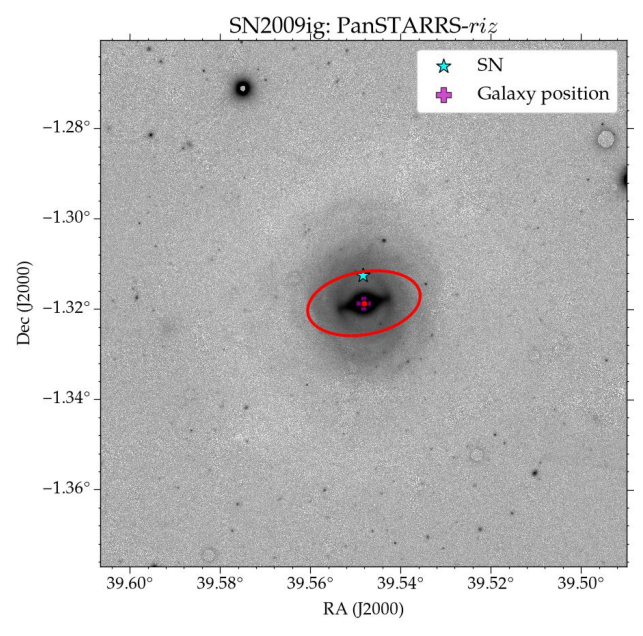

In [7]:
_ = gp.extract_aperture(name, host_ra, host_dec, filt='riz', survey='PanSTARRS',
                        ra=ra, dec=dec, aperture_method='kron')
plot_image(f'images/{name}/PanSTARRS/global_PanSTARRS_riz.jpg')

In [8]:
kron = gp.multi_band_phot(name, host_ra, host_dec, survey='PanSTARRS',
                          common_aperture=True, ref_filt='riz', ref_survey='PanSTARRS',
                          aperture_method='kron', save_plots=False, save_results=False)

The curve-of-growth (CoG) aperture (`aperture_method="cog"`) measures the profile of the galaxy in elliptical annuli out to where it is no longer significant, and estimates the flux beyond it with a Sérsic fit (out to 8 effective radii). Its uncertainty includes that of the tail:

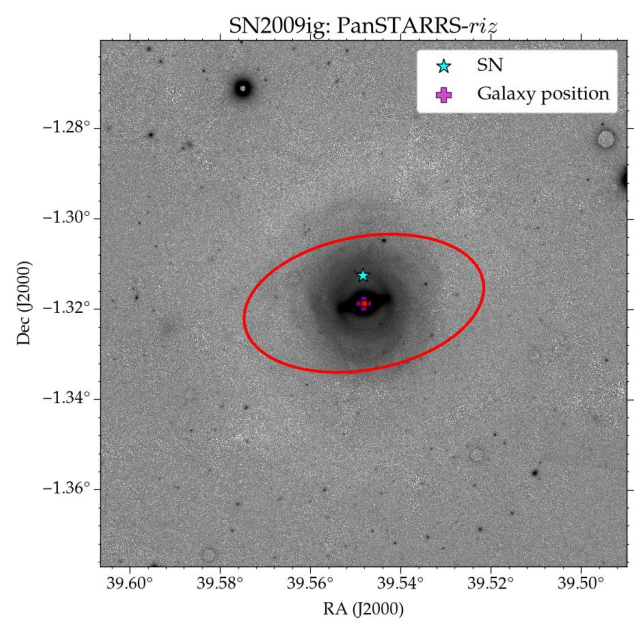

In [9]:
_ = gp.extract_aperture(name, host_ra, host_dec, filt='riz', survey='PanSTARRS',
                        ra=ra, dec=dec, aperture_method='cog')
plot_image(f'images/{name}/PanSTARRS/global_PanSTARRS_riz.jpg')

In [10]:
cog = gp.multi_band_phot(name, host_ra, host_dec, survey='PanSTARRS',
                         common_aperture=True, ref_filt='riz', ref_survey='PanSTARRS',
                         aperture_method='cog', save_plots=False, save_results=False)

comparison = pd.DataFrame({
    'Kron': [kron[f].iloc[0] for f in 'grizy'],
    'Kron err': [kron[f'{f}_err'].iloc[0] for f in 'grizy'],
    'CoG': [cog[f].iloc[0] for f in 'grizy'],
    'CoG err': [cog[f'{f}_err'].iloc[0] for f in 'grizy'],
}, index=list('grizy')).round(3)
comparison['CoG - Kron'] = (comparison['CoG'] - comparison['Kron']).round(3)
comparison

,Kron,Kron err,CoG,CoG err,CoG - Kron
g,13.237,0.019,12.730,0.162,-0.507
r,12.492,0.022,11.980,0.166,-0.512
i,12.140,0.019,11.664,0.160,-0.476
z,11.987,0.020,11.506,0.162,-0.481
y,11.658,0.024,11.164,0.162,-0.494


The CoG magnitudes are ~0.5 mag brighter, as the Kron aperture follows the bar and misses most of the disc. The CoG uncertainties are larger, mainly from the Sérsic tail (~20% of the flux for this galaxy, see `tail_frac` below). The uncertainties of the global photometry include the background noise (with a noise floor from blank apertures, for correlated noise), the uncertainty of the sky level within the aperture, which is significant for large apertures, and, for the CoG aperture, that of the Sérsic tail.

The aperture parameters are saved in a CSV file, including the ellipse on the sky (`ra`, `dec`, `a_arcsec`, `b_arcsec`, `pa_deg`; the semi-axes of the measured ellipse, to be scaled by `kronrad * scale`) and, for the CoG aperture, the Sérsic fit and the fraction of the flux in the tail:

In [11]:
params = pd.read_csv(f'images/{name}/PanSTARRS/aperture_parameters_riz.csv')
params[['ra', 'dec', 'a_arcsec', 'b_arcsec', 'pa_deg', 'kronrad', 'scale',
        'method', 'sersic_n', 'tail_frac', 'tail_frac_err']]

,ra,dec,a_arcsec,b_arcsec,pa_deg,kronrad,scale,method,sersic_n,tail_frac,tail_frac_err
0,39.548123,-1.318707,8.91951,4.895604,100.51647,2.036946,5.322497,cog,7.846182,0.21835,0.17468


## Other surveys

With `common_aperture=True`, the aperture of the reference (`ref_filt`, `ref_survey`) is used for all the filters, transferred through its ellipse on the sky, which is exact for any pixel scale and orientation of the images (only the CSV file with the parameters is needed, not the reference image). With the CoG aperture, the tail fraction of the reference is also applied to all the filters:

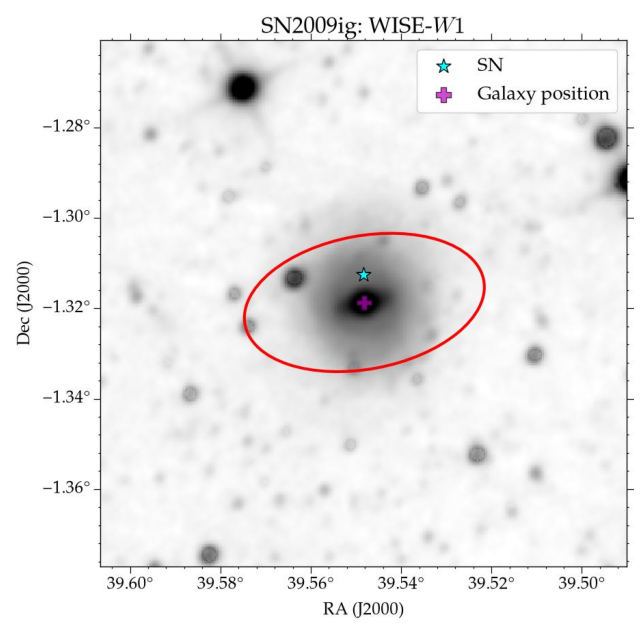

In [12]:
results = {}
for survey in surveys:
    results[survey] = gp.multi_band_phot(name, host_ra, host_dec, survey=survey, ra=ra, dec=dec,
                                         common_aperture=True, ref_filt='riz', ref_survey='PanSTARRS',
                                         aperture_method='cog', save_plots=True, raise_exception=False)
plot_image(f'images/{name}/WISE/global_WISE_W1.jpg')

## Outputs and quality flags

Each filter has the magnitude in the survey system (`{filt}`, `{filt}_err`; e.g. Vega for 2MASS and WISE), the AB magnitude (`{filt}_AB`), the flux density in µJy (`{filt}_flux_uJy`, `{filt}_flux_uJy_err`) and the 3-sigma upper limit (`{filt}_AB_ulim`), so that all the surveys can be compared directly:

In [13]:
rows = []
for survey, df in results.items():
    for filt in get_survey_filters(survey):
        if f'{filt}_AB' in df.columns:
            rows.append([survey, filt] + [df[f'{filt}{col}'].iloc[0] for col in
                                          ['', '_err', '_AB', '_flux_uJy', '_flux_uJy_err', '_AB_ulim']])
outputs = pd.DataFrame(rows, columns=['survey', 'filter', 'mag', 'mag_err', 'AB', 'flux_uJy',
                                      'flux_uJy_err', 'AB_ulim'])
outputs.round(3)

,survey,filter,mag,mag_err,AB,flux_uJy,flux_uJy_err,AB_ulim
0,PanSTARRS,g,12.730,0.162,12.730,29388.590,4377.925,13.604
1,PanSTARRS,r,11.980,0.166,11.980,58591.143,8948.289,12.828
2,PanSTARRS,i,11.664,0.160,11.664,78406.887,11581.192,12.548
3,PanSTARRS,z,11.506,0.162,11.506,90661.671,13520.510,12.380
4,PanSTARRS,y,11.164,0.162,11.164,124316.834,18602.440,12.033
5,2MASS,J,10.310,0.156,11.220,118066.950,17003.687,12.131
6,2MASS,H,9.618,0.158,11.008,143492.208,20845.370,11.910
7,2MASS,Ks,9.406,0.158,11.256,114157.258,16648.957,12.154
8,WISE,W1,8.962,0.156,11.661,78611.650,11280.337,12.576
9,WISE,W2,8.909,0.156,12.248,45772.940,6580.725,13.162


Some issues do not prevent the photometry from being measured but make it less reliable. They are reported with a warning and with a boolean column for each filter (`{filt}_{flag}_flag`), so that the user can decide whether to use each measurement:

In [14]:
import hostphot.flags
print(hostphot.flags.__doc__.split('Flags:')[1])



- ``bkg``: the subtracted background is unreliable in the aperture (e.g. the galaxy fills most of the image);
  see :func:`hostphot.processing.background.background_flag`.
- ``coverage``: part of the aperture has no data (e.g. image edge or chip gap). Local apertures: the flux is
  measured from the remaining pixels and might be underestimated (by up to 5%). Global apertures: the estimated
  missing flux (up to 10%, assuming a symmetric galaxy) is added to the flux, and half of it to the uncertainty.
- ``psf``: the aperture radius is smaller than the PSF FWHM (local photometry only).
- ``err``: the blank-aperture noise floor could not be estimated, or was extrapolated from smaller apertures,
  so the uncertainty might be underestimated; or it was estimated from blank apertures far from the source,
  as those near it were contaminated (e.g. by faint galaxy light).
- ``aperture``: the global aperture might not include all the flux of the galaxy (global photometry only): the
  optimised

In [15]:
for survey, df in results.items():
    flags = [col for col in df.columns if col.endswith('_flag') and bool(df[col].iloc[0])]
    print(f'{survey}: {flags if flags else "no flags"}')

PanSTARRS: ['r_err_flag', 'i_err_flag']
2MASS: ['J_err_flag']
WISE: ['W1_err_flag', 'W2_err_flag', 'W3_err_flag', 'W4_bkg_flag']


The outputs also include the HostPhot version and, for each image, an identifier and its download date (`{filt}_image_id`, `{filt}_download_date`), so that the results can be traced back to the images used.

## SED

Finally, the SED of the galaxy (`plot_flux=True` plots the flux densities in µJy; non-detections are shown as upper limits):

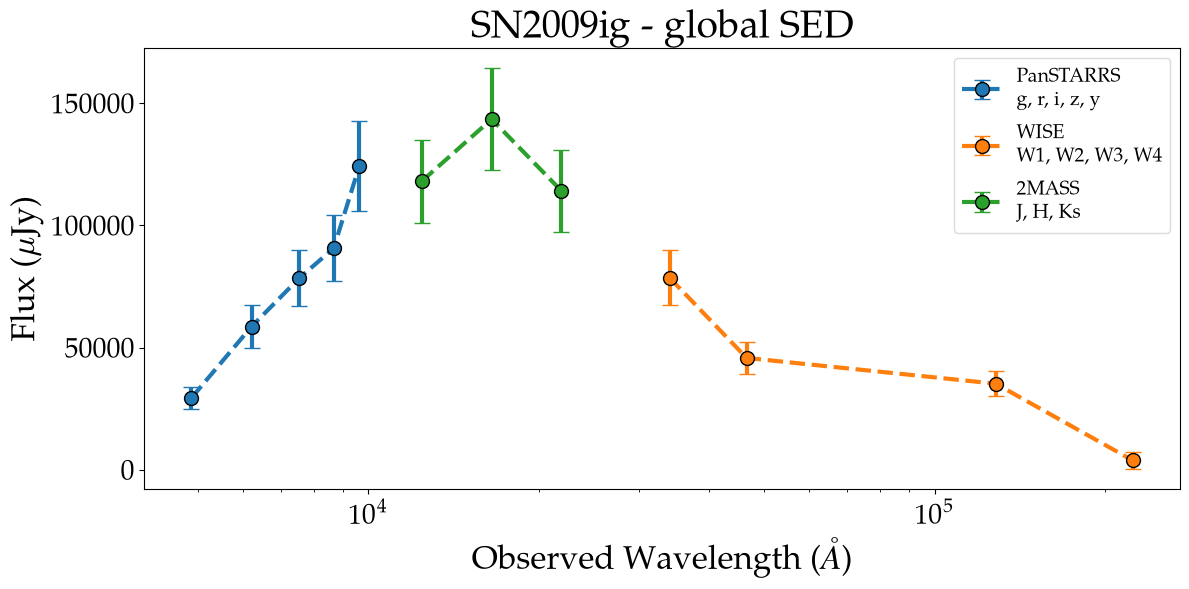

In [16]:
from hostphot.photometry.sed_plotting import plot_sed

plot_sed(name, phot_type='global', plot_flux=True)